# Ground Water Resource Extraction and Refilling - EDA

#### There is a famous say if there is a third world war, the war will be fought for the water. India is an enormous country with very diverse lifestyles. India is a country of many famous rivers flowing across the country and the world's highest rainfall zone is in India. Though, due to unplanned usage and wastage of water, many of the states in India is f facing a severe shortage of water during summer.

#### Content
##### This dataset contains 689 rows for each district in India and 16 columns for different statistical data related to water extraction and recharge. The dataset contains data for the year 2017.

#### Inspiration
##### In recent times, India is going through a severe water crisis in many of the regions during the summer. Proper planning and forecasting can save wastage of water. Distribution of water and regulating the extraction of groundwater can be done more efficiently by analyzing the dataset.

#### Acknowledgment
##### The dataset is provided by https://data.gov.in/. The dataset is open for analysis and research.

## Data Processing

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# Any results you write to the current directory are saved as output.

/kaggle/input/districtwise-ground-water-resources-by-july-2017/Dynamic_2017_2_0.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/kaggle/input/districtwise-ground-water-resources-by-july-2017/Dynamic_2017_2_0.csv')

In [ ]:
df.shape

(689, 16)

In [ ]:
df.sample(10)

,S.no.,Name of State,Name of District,Recharge from rainfall During Monsoon Season,Recharge from other sources During Monsoon Season,Recharge from rainfall During Non Monsoon Season,Recharge from other sources During Non Monsoon Season,Total Annual Ground Water Recharge,Total Natural Discharges,Annual Extractable Ground Water Resource,Current Annual Ground Water Extraction For Irrigation,Current Annual Ground Water Extraction For Domestic & Industrial Use,Total Current Annual Ground Water Extraction,Annual GW Allocation for Domestic Use as on 2025,Net Ground Water Availability for future use,Stage of Ground Water Extraction (%)
137,138,GUJARAT,Amreli,104008.67,11261.72,0.00,10873.04,126143.43,6307.17,119836.26,70915.60,2344.18,73259.78,2600.00,45969.04,61.13
445,446,PUNJAB,Barnala,11860.00,36439.26,2291.59,13763.61,64354.46,6435.45,57919.01,119753.01,2339.71,122092.72,3217.10,0.00,210.80
656,657,WEST BENGAL,Uttar Dinajpur,91467.43,7541.41,22166.67,24353.83,145529.34,12014.51,133514.83,78133.60,4811.27,82944.87,7569.33,47811.90,62.00
124,125,DELHI,New Delhi,1852.76,191.09,371.00,1014.21,3429.06,212.43,3216.63,955.13,4172.89,5128.02,4046.05,0.00,159.42
355,356,MAHARASHTRA,Latur,45726.03,6929.64,0.00,16210.55,68866.23,3453.20,65413.03,34270.64,2142.34,36412.97,4126.61,27018.98,55.67
216,217,J&K,Doda,504.82,18.86,1880.21,23.05,2426.94,242.69,2184.25,105.12,574.74,679.86,557.14,1504.39,31.13
383,384,MANIPUR,Ukhrul,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
177,178,HARYANA,Jind,17583.72,27872.43,9836.80,32166.17,87459.12,8745.90,78713.22,99849.00,2188.00,102037.00,2804.00,6927.32,129.63
100,101,CHATTISGARH,Bijapur,34518.65,188.02,4178.56,562.23,39447.46,3944.74,35502.72,1874.06,620.63,2494.70,689.28,32938.55,7.03
473,474,RAJASTHAN,Bikaner,25309.35,238.29,0.00,1056.16,26603.80,2505.27,24098.53,33254.17,7780.14,41034.31,10097.11,3056.66,170.28


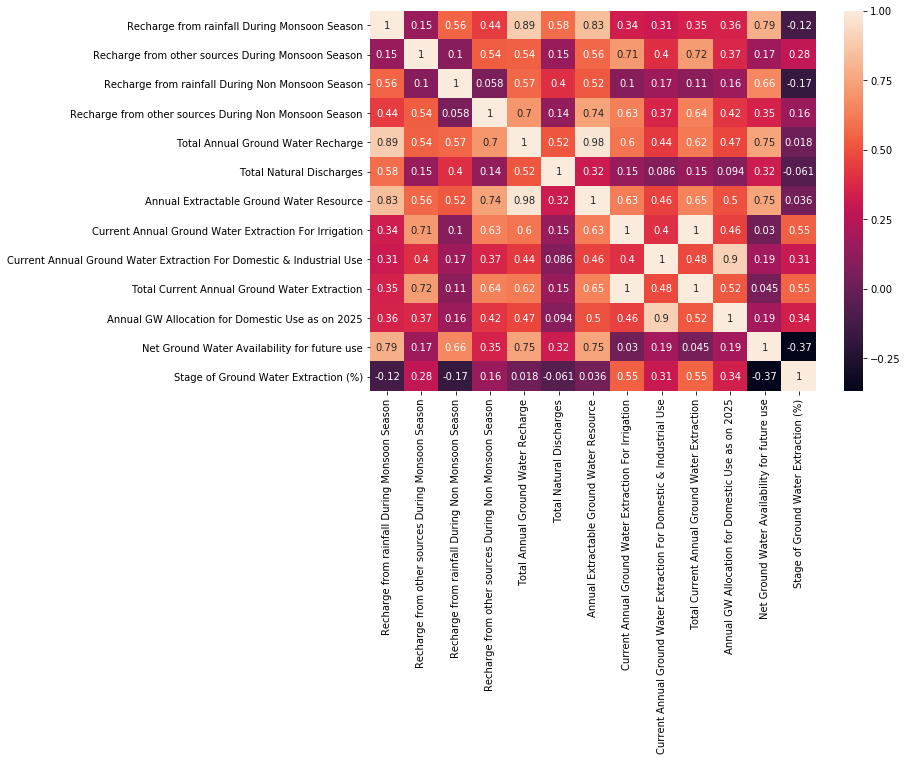

In [ ]:
df.drop('S.no.', axis =1, inplace = True)
f, ax = plt.subplots(figsize=(10,7))
sns.heatmap(df.corr(), annot = True)
plt.show()

In [ ]:
#Get information on the columns, null values in the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 689 entries, 0 to 688
Data columns (total 15 columns):
Name of State                                                           689 non-null object
Name of District                                                        689 non-null object
Recharge from rainfall During Monsoon Season                            684 non-null float64
Recharge from other sources During Monsoon Season                       684 non-null float64
Recharge from rainfall During Non Monsoon Season                        684 non-null float64
Recharge from other sources During Non Monsoon Season                   684 non-null float64
Total Annual Ground Water Recharge                                      684 non-null float64
Total Natural Discharges                                                684 non-null float64
Annual Extractable Ground Water Resource                                684 non-null float64
Current Annual Ground Water Extraction For Irrigation       

In [ ]:
df.isna().sum()

Name of State                                                           0
Name of District                                                        0
Recharge from rainfall During Monsoon Season                            5
Recharge from other sources During Monsoon Season                       5
Recharge from rainfall During Non Monsoon Season                        5
Recharge from other sources During Non Monsoon Season                   5
Total Annual Ground Water Recharge                                      5
Total Natural Discharges                                                5
Annual Extractable Ground Water Resource                                5
Current Annual Ground Water Extraction For Irrigation                   5
Current Annual Ground Water Extraction For Domestic & Industrial Use    0
Total Current Annual Ground Water Extraction                            5
Annual GW Allocation for Domestic Use as on 2025                        5
Net Ground Water Availability for futu

In [ ]:
#statewise groundwater reserve
state_list = []
total_frnd_water_recharge = []
curr_gw_extr_list = []
future_available_GW_list = []
#Net Ground Water Availability for future use

for state, subset in df.groupby('Name of State'):
    #print(state, sum(subset['Net Ground Water Availability for future use']))
    state_list.append(state)
    total_frnd_water_recharge.append(sum(subset['Total Annual Ground Water Recharge']))
    curr_gw_extr_list.append(sum(subset['Total Current Annual Ground Water Extraction']))
    future_available_GW_list.append(sum(subset['Net Ground Water Availability for future use'])) 
dfnew = pd.DataFrame({"State":state_list, "GW_Recharge":total_frnd_water_recharge, "GW_Extraction": curr_gw_extr_list, "Future_GW_Available": future_available_GW_list})

## Exploratory data Analysis (EDA)

### Total Rechage, Extraction, Future Availability and Annual Reserve by States in India

In [ ]:
dfnew.sort_values(['GW_Recharge','GW_Extraction'], inplace= True)
dfnew['annual_reserve'] = dfnew['GW_Recharge']-dfnew['GW_Extraction']
dfnew

,State,GW_Recharge,GW_Extraction,Future_GW_Available,annual_reserve
10,Diu,471.00,386.00,6.00,85.00
19,LAKSHADWEEP,1072.80,238.10,122.81,834.70
9,Daman,1304.00,635.00,480.00,669.00
5,CHANDIGARH,4216.00,3378.00,416.00,838.00
8,Dadra & Nagar Haveli,6861.59,2042.86,4475.73,4818.73
24,MIZORAM,21280.76,731.88,18092.91,20548.88
28,Puducherry,22633.18,15140.82,5473.84,7492.36
11,GOA,26722.34,5371.36,6992.81,21350.98
7,DELHI,32100.02,35990.29,2299.43,-3890.27
0,A&N ISLAND,36841.83,908.17,32131.52,35933.66


### Annual Reserve of Ground water by states, Green bars indicate positive annual reserve, while Red value indicates negative annual reserve.

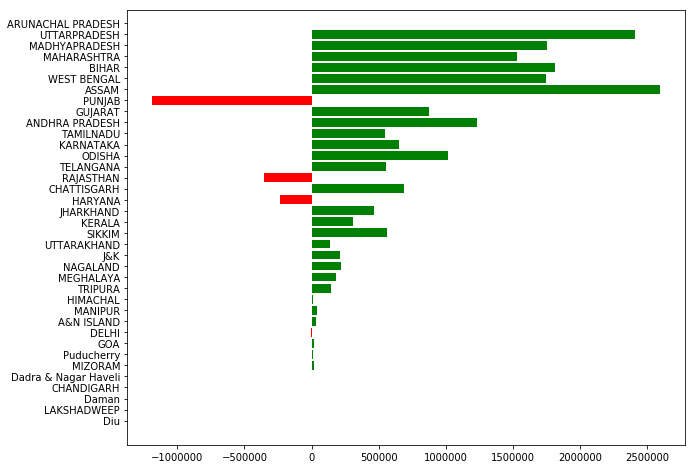

In [ ]:
f, ax = plt.subplots(figsize=(10,8))
plt.barh(dfnew['State'],dfnew['annual_reserve'], color=(dfnew['annual_reserve']>0).map({True: 'g',False: 'r'}))
plt.show()

#### Following analysis indiates Groundwater Extraction vs Availability,Data shows Haryana, Rajasthan, Punjab, Delhi are in critial zone as Ground water Extraction is almost equal to the availability. If groundwater distribution is not planned properly, severe shortage of water can happen in future.

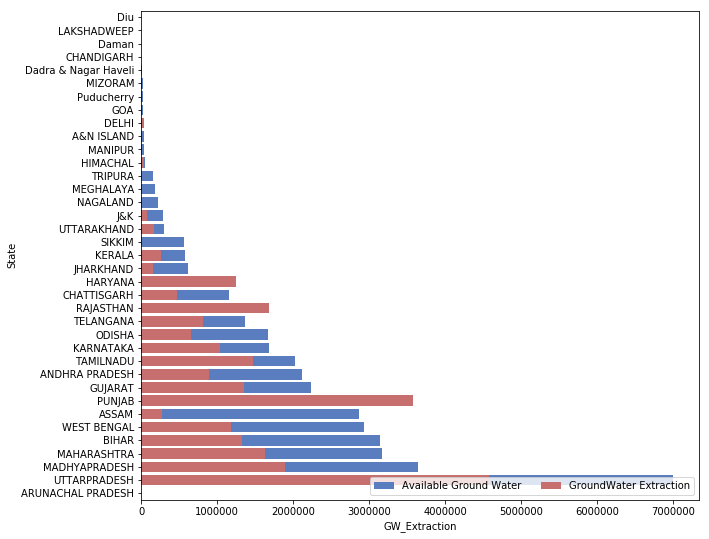

In [ ]:
f, ax = plt.subplots(figsize=(10, 9))

sns.set_color_codes("muted")
sns.barplot(x='GW_Recharge', y= 'State', data = dfnew, label = 'Available Ground Water', color='b')
sns.barplot(x='GW_Extraction', y= 'State', data = dfnew, label = 'GroundWater Extraction', color='r')
ax.legend(ncol=2, loc="lower right", frameon=True)
plt.show()

#### Future Ground water availability in different states in India, No data available for ArunachalPradesh, Other than that Assam , UttarPradesh, Madhya Pradesh and Bihar has higher future Reserve.

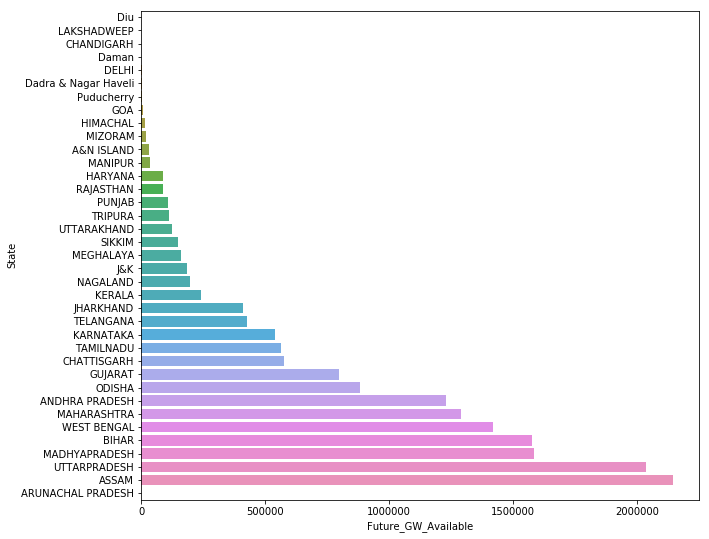

In [ ]:
dfnew.sort_values('Future_GW_Available', inplace = True)
f, ax = plt.subplots(figsize=(10, 9))
sns.barplot(x='Future_GW_Available', y = 'State',data = dfnew)
plt.show()

In [ ]:
dfnew.count()

State                  37
GW_Recharge            36
GW_Extraction          36
Future_GW_Available    36
annual_reserve         36
dtype: int64

#### We will dig litter deeper and check the Distric level scenario in West-Bengal

In [ ]:
df_westbengal = df[df['Name of State']=='WEST BENGAL']
df_westbengal.head()

,Name of State,Name of District,Recharge from rainfall During Monsoon Season,Recharge from other sources During Monsoon Season,Recharge from rainfall During Non Monsoon Season,Recharge from other sources During Non Monsoon Season,Total Annual Ground Water Recharge,Total Natural Discharges,Annual Extractable Ground Water Resource,Current Annual Ground Water Extraction For Irrigation,Current Annual Ground Water Extraction For Domestic & Industrial Use,Total Current Annual Ground Water Extraction,Annual GW Allocation for Domestic Use as on 2025,Net Ground Water Availability for future use,Stage of Ground Water Extraction (%)
653,WEST BENGAL,Coochbehar,185334.09,5143.37,60379.13,12100.71,262957.30,26295.71,236661.59,42261.5,4447.27,46708.77,5988.25,188411.84,20.0
654,WEST BENGAL,Jalpaiguri,228086.62,3939.51,65301.46,12078.29,309405.88,30940.59,278465.29,8241.2,4395.75,12636.95,5908.97,264315.12,5.0
655,WEST BENGAL,Darjeeling,39186.21,0.00,13052.71,0.00,52238.92,5223.89,47015.03,1169.1,1478.05,2647.15,2012.74,43833.19,6.0
656,WEST BENGAL,Uttar Dinajpur,91467.43,7541.41,22166.67,24353.83,145529.34,12014.51,133514.83,78133.6,4811.27,82944.87,7569.33,47811.90,62.0
657,WEST BENGAL,Dakshin Dinajpur,65504.74,6432.72,17257.72,18756.55,107951.73,9115.64,98836.09,50706.0,2618.71,53324.71,3349.33,44780.76,54.0


In [ ]:
for state in list(df['Name of State'].unique()):
    print(state)

ANDHRA PRADESH
ARUNACHAL PRADESH
ASSAM
BIHAR
CHATTISGARH
DELHI
GOA
GUJARAT
HARYANA
HIMACHAL
J&K
JHARKHAND
KARNATAKA
KERALA
MADHYAPRADESH
MAHARASHTRA
MANIPUR
MEGHALAYA
MIZORAM
NAGALAND
ODISHA
PUNJAB
RAJASTHAN
SIKKIM
TAMILNADU
TELANGANA
TRIPURA
UTTARPRADESH
UTTARAKHAND
WEST BENGAL
A&N ISLAND
CHANDIGARH
Dadra & Nagar Haveli
Daman
Diu
LAKSHADWEEP
Puducherry


* ##### Annual Ground-water allocation estimated to the districts in West-Bengal. North-24_Parganas, Murshidabad and Burdwan are top 3 estimated districtics by Ground water allocation 

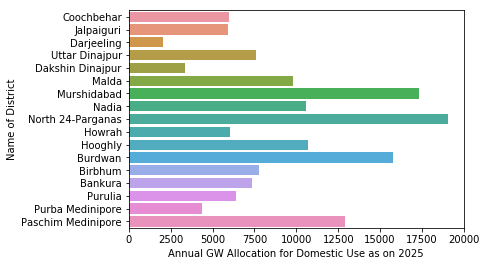

In [ ]:

sns.barplot(x = 'Annual GW Allocation for Domestic Use as on 2025', y = 'Name of District', data = df[df['Name of State']=='WEST BENGAL'])
plt.show()

In [ ]:
df_westbengal.sort_values('Stage of Ground Water Extraction (%)',ascending=False, inplace = True)
df_westbengal[['Name of State','Name of District','Stage of Ground Water Extraction (%)']].head(3)

/opt/conda/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


,Name of State,Name of District,Stage of Ground Water Extraction (%)
660,WEST BENGAL,Nadia,92.0
659,WEST BENGAL,Murshidabad,87.0
661,WEST BENGAL,North 24-Parganas,66.0


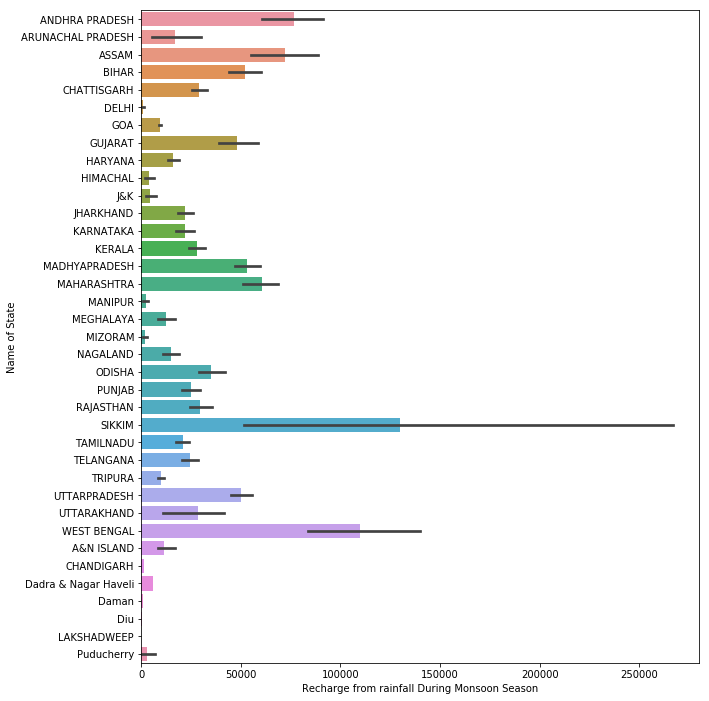

In [ ]:
plt.figure(figsize=(10,12))
sns.barplot(x='Recharge from rainfall During Monsoon Season', y='Name of State', data = df)
plt.show()

#### State-wise Ground Water Extraction Distributions statistics. 

0 UTTARPRADESH
1 MADHYAPRADESH
2 BIHAR
3 MAHARASHTRA
4 RAJASTHAN
5 GUJARAT
6 TAMILNADU
7 TELANGANA
8 KARNATAKA
9 ODISHA
10 ASSAM
11 CHATTISGARH
12 JHARKHAND
13 J&K
14 PUNJAB
15 HARYANA
16 WEST BENGAL
17 ARUNACHAL PRADESH
18 KERALA
19 ANDHRA PRADESH
20 DELHI
21 MEGHALAYA
22 NAGALAND
23 MANIPUR
24 LAKSHADWEEP
25 MIZORAM
26 HIMACHAL


/opt/conda/lib/python3.6/site-packages/numpy/lib/histograms.py:839: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
/opt/conda/lib/python3.6/site-packages/numpy/lib/histograms.py:840: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


27 TRIPURA
28 UTTARAKHAND
29 SIKKIM
30 Puducherry
31 A&N ISLAND
32 GOA
33 CHANDIGARH
34 Dadra & Nagar Haveli
35 Daman


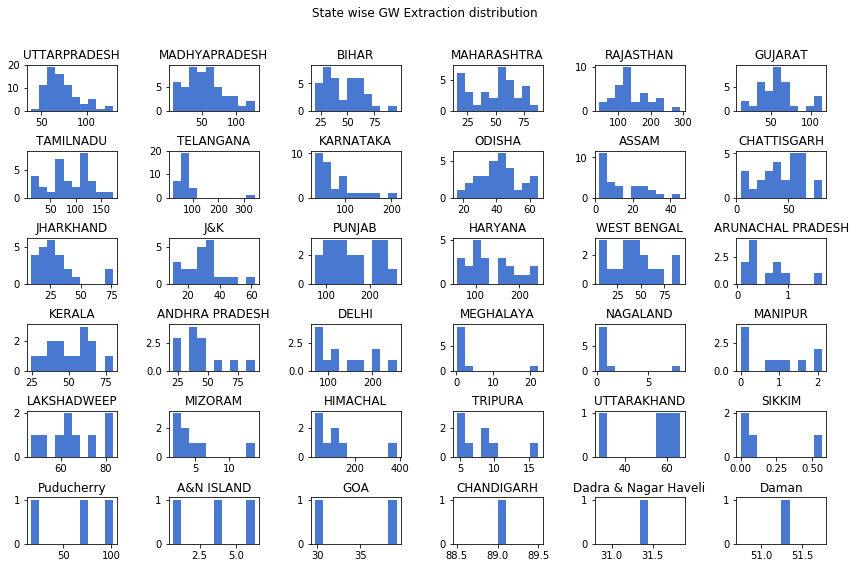

In [ ]:
fig,axs = plt.subplots(6,6,figsize=(12,8))

for idx,state in enumerate(df['Name of State'].value_counts().sort_values(ascending=False)[0:36].index):
    print(idx,state)
    axs[idx//6,idx%6].hist(x = df[df['Name of State']==state]['Stage of Ground Water Extraction (%)'], color='b')
    axs[idx//6,idx%6].set_title(state)
plt.suptitle("State wise GW Extraction distribution")
plt.tight_layout()
fig.subplots_adjust(top=0.88)
plt.show()

## Future Scope
#### This analysis has further analysis scopes, 
##### We can analysis Ground water allocation per capita per state
##### Analysis can be done access to drinking water percentage state wise
##### We can analyze the Ground water availability based on Land area in states
##### We can analyse further based on water body available in the states.
